# DNS Trace Analysis & Blocklist Analysis

In [1]:
import sys
!{sys.executable} -m pip install dpkt pandas tqdm pyarrow tqdm

In [2]:
# CONFIGURATION
import dpkt
import socket
import pandas as pd
import os
import json
import matplotlib.pyplot as plt
import seaborn as sns
BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if '__file__' in globals() else os.getcwd()
DATA_DIR = os.path.join(BASE_DIR, 'data')
DATASET_DIR = os.path.join(DATA_DIR, "02_octopus")
PIHOLE_DIR = os.path.join(DATASET_DIR, "pihole")
FTL_PATH = os.path.join(PIHOLE_DIR, "pihole-FTL.db")
FTL_PATH_FIX = os.path.join(PIHOLE_DIR, "pihole-FTL.db_fixed.db")
if os.path.exists(FTL_PATH_FIX):
    FTL_PATH = FTL_PATH_FIX

if not os.path.exists(FTL_PATH):
    raise FileNotFoundError(f"File not found: {FTL_PATH}")
GRAVITY_PATH = os.path.join(PIHOLE_DIR, "gravity.db")

# Load Data from Table

In [3]:
import sqlite3

def inspect_ftl(path):
    try:
        conn = sqlite3.connect(path)
        cursor = conn.cursor()

        # Get all tables
        tables = cursor.execute("SELECT name FROM sqlite_master WHERE type='table';").fetchall()
        print(f"--- Tables found in FTL: {[t[0] for t in tables]} ---\n")

        # The most important tables for data analysis
        target_tables = ['queries', 'client_by_id', 'forward_by_id', 'network']

        for table in target_tables:
            if any(table in t for t in tables):
                print(f"Columns in '{table}':")
                columns = cursor.execute(f"PRAGMA table_info({table});").fetchall()
                for col in columns:
                    # col[1] is name, col[2] is data type
                    print(f"  - {col[1]} ({col[2]})")
                print("-" * 30)

        conn.close()
    except sqlite3.DatabaseError as e:
        print(f"FTL connection failed: {e}")

inspect_ftl(FTL_PATH)

--- Tables found in FTL: ['query_storage', 'sqlite_sequence', 'ftl', 'counters', 'message', 'network_addresses', 'network', 'aliasclient', 'domain_by_id', 'client_by_id', 'forward_by_id', 'addinfo_by_id', 'session', 'sqlite_stat1'] ---

Columns in 'client_by_id':
  - id (INTEGER)
  - ip (TEXT)
  - name (TEXT)
------------------------------
Columns in 'forward_by_id':
  - id (INTEGER)
  - forward (TEXT)
------------------------------
Columns in 'network':
  - id (INTEGER)
  - hwaddr (TEXT)
  - interface (TEXT)
  - firstSeen (INTEGER)
  - lastQuery (INTEGER)
  - numQueries (INTEGER)
  - macVendor (TEXT)
  - aliasclient_id (INTEGER)
------------------------------


In [4]:
import sqlite3
import pandas as pd

# Connect and load
with sqlite3.connect(FTL_PATH) as conn:
    # Get queries
    df = pd.read_sql_query("""
        SELECT
            datetime(timestamp, 'unixepoch', 'localtime') AS time,
            client,
            domain,
            status
        FROM queries
    """, conn)

    # Get status mapping if you want human-readable labels
    # (Optional, but highly recommended)
    status_map = {
        0: "Unknown",
        1: "Blocked (Gravity)",
        2: "Forwarded",
        3: "Cached",
        4: "Blocked (Regex)",
        5: "Blocked (Exact)",
        6: "Blocked (Upstream IP)",
        7: "Blocked (Upstream 0.0.0.0/::)",
        8: "Blocked (Upstream NXDOMAIN)",
        9: "Blocked (CNAME Gravity)",
        10: "Blocked (CNAME Regex)",
        11: "Blocked (CNAME Exact)",
        12: "Retried",
        13: "Retried (Ignored/DNSSEC)",
        14: "Already Forwarded",
        15: "Blocked (Database busy)",
        16: "Blocked (Special domain)",  # e.g., Apple Private Relay
        17: "Cached (Stale)",
        18: "Blocked (Upstream EDE 15)"
    }
    df['status_label'] = df['status'].map(status_map).fillna("Other/Unknown")

df.head()

,time,client,domain,status,status_label
0,2026-07-13 11:55:56,172.31.250.143,dl.google.com,2,Forwarded
1,2026-07-13 11:55:56,172.31.250.144,dl.google.com,14,Already Forwarded
2,2026-07-13 11:55:56,172.31.250.157,dl.google.com,14,Already Forwarded
3,2026-07-13 11:55:56,172.31.250.157,dl.google.com,3,Cached
4,2026-07-13 11:55:56,172.31.250.144,dl.google.com,3,Cached


In [5]:
print(f"Total records salvaged: {len(df)}")

Total records salvaged: 299918


In [6]:
import sqlite3
import pandas as pd

def get_unique_client_stats(db_path):
    # Using a context manager ensures the connection closes even if an error occurs
    with sqlite3.connect(db_path) as conn:
        # Changed q.rowid to q.timestamp for compatibility
        query = """
            SELECT
                n.id AS unique_id,
                n.hwaddr AS mac_address,
                n.macVendor,
                COUNT(q.timestamp) as total_queries
            FROM queries q
            JOIN network_addresses na ON q.client = na.ip
            JOIN network n ON na.network_id = n.id
            GROUP BY n.id
            ORDER BY total_queries DESC
        """
        try:
            df_clients = pd.read_sql_query(query, conn)

            unique_count = df_clients['unique_id'].nunique()

            print(f"--- Client Analysis ---")
            print(f"Total Unique Hardware Clients Found: {unique_count}")
            print("\nTop Clients by Activity:")
            print(df_clients)

            return df_clients
        except Exception as e:
            print(f"Error executing query: {e}")
            return None

# Execute
df_unique_clients = get_unique_client_stats(FTL_PATH)

Error executing query: Could not decode to UTF-8 column 'macVendor' with text '8����'


<Axes: title={'center': 'Network Traffic Composition'}, ylabel='count'>

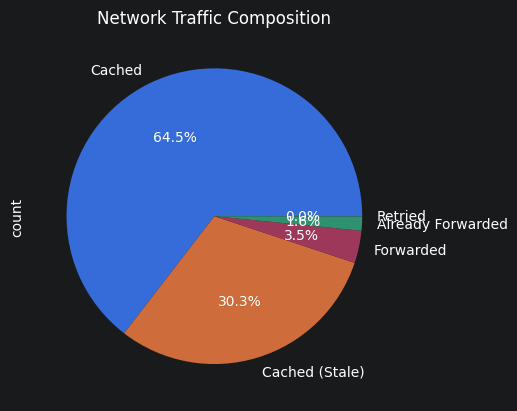

In [7]:
# Visualize the Block Rate
block_counts = df['status_label'].value_counts()
block_counts.plot(kind='pie', autopct='%1.1f%%', title=f"Network Traffic Composition")

In [8]:
import sqlite3
import pandas as pd

# We assume FTL_PATH is already defined in your notebook
conn = sqlite3.connect(FTL_PATH)

# Using a LEFT JOIN to ensure we get hardware info even if no 'friendly name' exists
query = """
SELECT
    n.id AS network_id,
    c.ip,
    c.name AS friendly_name,
    n.hwaddr AS mac_address,
    n.macVendor AS vendor,
    n.numQueries AS total_queries,
    datetime(n.firstSeen, 'unixepoch', 'localtime') AS first_seen,
    datetime(n.lastQuery, 'unixepoch', 'localtime') AS last_active,
    n.interface
FROM network n
LEFT JOIN client_by_id c ON n.id = c.id
ORDER BY n.numQueries DESC
"""

df_all_clients = pd.read_sql_query(query, conn)
conn.close()

# Clean up: Replace NaN in vendor/name for better readability
df_all_clients['vendor'] = df_all_clients['vendor'].fillna('Unknown Vendor')
df_all_clients['friendly_name'] = df_all_clients['friendly_name'].fillna('Unnamed Device')

# Display result
display(df_all_clients)

DatabaseError: Execution failed on sql '
SELECT
    n.id AS network_id,
    c.ip,
    c.name AS friendly_name,
    n.hwaddr AS mac_address,
    n.macVendor AS vendor,
    n.numQueries AS total_queries,
    datetime(n.firstSeen, 'unixepoch', 'localtime') AS first_seen,
    datetime(n.lastQuery, 'unixepoch', 'localtime') AS last_active,
    n.interface
FROM network n
LEFT JOIN client_by_id c ON n.id = c.id
ORDER BY n.numQueries DESC
': Could not decode to UTF-8 column 'vendor' with text '8����'

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import pandas as pd

# Using your defined FTL_PATH
conn = sqlite3.connect(FTL_PATH)
df = pd.read_sql_query("SELECT numQueries FROM network WHERE numQueries > 0", conn)
conn.close()

df.head()

In [ ]:
# Set the visual style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Histogram with KDE (Log Scale)
sns.histplot(df['numQueries'], kde=True, ax=axes[0], color='teal', log_scale=True)
axes[0].set_title('Distribution of Total Queries (Log Scale)', fontsize=14)
axes[0].set_xlabel('Number of Queries', fontsize=12)
axes[0].set_ylabel('Device Count', fontsize=12)

# 2. Boxplot (Log Scale) to show outliers
sns.boxplot(x=df['numQueries'], ax=axes[1], color='orange')
axes[1].set_xscale('log')
axes[1].set_title('Boxplot of Total Queries (Log Scale)', fontsize=14)
axes[1].set_xlabel('Number of Queries', fontsize=12)

plt.tight_layout()
plt.show()

# Print the descriptive statistics for your paper/notes
print("Summary Statistics:")
print(df['numQueries'].describe())

In [ ]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Map based on Pi-hole FTL status codes
status_map = {
    1: "Blocked (Gravity)",
    2: "Forwarded",
    3: "Cached",
    4: "Blocked (Wildcard)",
    5: "Blocked (Blacklist)",
    9: "Blocked (CNAME)",
    12: "Retried",
    14: "Already Forwarded"
}

def plot_status_distribution(path):
    conn = sqlite3.connect(path)

    # We pull all statuses from query_storage
    df_status = pd.read_sql_query("SELECT status FROM query_storage", conn)
    conn.close()

    # Map the integers to strings
    df_status['status_name'] = df_status['status'].map(status_map).fillna("Other/Unknown")

    # Calculate percentages for the plot
    counts = df_status['status_name'].value_counts()
    percentages = (counts / len(df_status) * 100).round(1)

    # Visualization
    plt.figure(figsize=(12, 6))
    sns.set_theme(style="whitegrid")

    ax = sns.countplot(data=df_status, y='status_name',
                       order=df_status['status_name'].value_counts().index,
                       palette='viridis')

    # Add percentage labels to the bars
    for i, p in enumerate(ax.patches):
        width = p.get_width()
        ax.text(width + 1, p.get_y() + p.get_height() / 2,
                f'{percentages.iloc[i]}%', va='center')

    plt.title('Distribution of Query Statuses', fontsize=15)
    plt.xlabel('Number of Queries', fontsize=12)
    plt.ylabel('Status Type', fontsize=12)
    plt.tight_layout()
    plt.show()

    return counts

# Run using your FTL_PATH variable
status_counts = plot_status_distribution(FTL_PATH)
print("Raw Counts:\n", status_counts)

In [ ]:
import sqlite3
import pandas as pd

# Status codes for blocked traffic
blocked_filter = "(1, 4, 5, 9)"

def get_readable_blocked_analysis(path):
    conn = sqlite3.connect(path)

    # We join query_storage (q) with domain_by_id (d) to get the string
    # We also try to join with client_by_id (c) for the IP/Name
    query = f"""
    SELECT
        d.domain,
        COUNT(*) as count
    FROM query_storage q
    JOIN domain_by_id d ON q.domain = d.id
    WHERE q.status IN {blocked_filter}
    GROUP BY q.domain
    ORDER BY count DESC
    LIMIT 20
    """

    try:
        df_domains = pd.read_sql_query(query, conn)

        # Also getting the client info while we are at it
        client_query = f"""
        SELECT
            c.ip,
            c.name,
            COUNT(*) as count
        FROM query_storage q
        JOIN client_by_id c ON q.client = c.id
        WHERE q.status IN {blocked_filter}
        GROUP BY q.client
        ORDER BY count DESC
        """
        df_clients = pd.read_sql_query(client_query, conn)

    finally:
        conn.close()

    return df_domains, df_clients

# Execute
df_blocked_domains, df_blocked_clients = get_readable_blocked_analysis(FTL_PATH)

print("--- Top 10 Blocked Domains (Resolved Names) ---")
display(df_blocked_domains.head(10))

print("\n--- Top Blocked Clients ---")
display(df_blocked_clients.head(10))

In [ ]:
import matplotlib.pyplot as plt
import sqlite3
import pandas as pd

if not df_blocked_domains.empty:
    # Use the first domain string from your resolved list
    top_domain_name = df_blocked_domains.iloc[0]['domain']

    def plot_domain_timeline(path, domain_name):
        conn = sqlite3.connect(path)
        # JOIN with domain_by_id to filter by the actual string name
        query = f"""
        SELECT q.timestamp
        FROM query_storage q
        JOIN domain_by_id d ON q.domain = d.id
        WHERE d.domain = '{domain_name}'
        """
        df_time = pd.read_sql_query(query, conn)
        conn.close()

        if df_time.empty:
            print(f"No timestamp data found for {domain_name}")
            return

        # 1. Convert to datetime
        df_time['time'] = pd.to_datetime(df_time['timestamp'], unit='s')

        # 2. Set the 'time' column as the index (Required for clean resampling)
        df_time = df_time.set_index('time')

        # 3. Resample and count occurrences per minute
        # We use 'T' or 'min' for minutes.
        timeline = df_time['timestamp'].resample('1min').count()

        # 4. Plotting
        plt.figure(figsize=(15, 5))

        # 'timeline' is now a Series where index is time and values are counts
        plt.plot(timeline.index, timeline.values, color='crimson', lw=1.5)
        plt.fill_between(timeline.index, timeline.values, color='crimson', alpha=0.1)

        plt.title(f'Blocking Activity Over Time: {domain_name}', fontsize=14)
        plt.xlabel('Time')
        plt.ylabel('Queries per Minute')
        plt.grid(True, linestyle='--', alpha=0.6)

        # Rotates labels so they don't overlap
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

    plot_domain_timeline(FTL_PATH, top_domain_name)
else:
    print("No blocked domains found to plot.")

In [ ]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_multi_domain_timeline(path, top_n=10):
    conn = sqlite3.connect(path)

    # Status codes: 1=Gravity, 4=Wildcard, 5=Blacklist, 9=CNAME
    blocked_filter = "(1, 4, 5, 9)"

    # Query to get timestamps and names for the top N blocked domains
    query = f"""
    SELECT
        datetime(q.timestamp, 'unixepoch', 'localtime') as time,
        d.domain
    FROM query_storage q
    JOIN domain_by_id d ON q.domain = d.id
    WHERE q.status IN {blocked_filter}
    AND d.domain IN (
        SELECT d2.domain
        FROM query_storage q2
        JOIN domain_by_id d2 ON q2.domain = d2.id
        WHERE q2.status IN {blocked_filter}
        GROUP BY d2.domain
        ORDER BY COUNT(*) DESC
        LIMIT {top_n}
    )
    """
    df = pd.read_sql_query(query, conn)
    conn.close()

    if df.empty:
        print("No blocked data found.")
        return

    # Prepare data
    df['time'] = pd.to_datetime(df['time'])

    # Resample to 5-minute buckets to make the dots more visible/meaningful
    # This counts how many times each domain was blocked in that 5min window
    df_resampled = df.groupby(['domain', pd.Grouper(key='time', freq='5min')]).size().reset_index(name='block_count')

    # Plotting
    plt.figure(figsize=(16, 8))
    sns.set_theme(style="whitegrid")

    # Use a scatter plot where:
    # X = Time
    # Y = Domain Name
    # Size = Number of blocks in that window
    scatter = sns.scatterplot(
        data=df_resampled,
        x='time',
        y='domain',
        size='block_count',
        hue='block_count',
        palette='rocket_r',
        sizes=(20, 400),
        alpha=0.7
    )

    plt.title(f'Temporal Distribution of Top {top_n} Blocked Domains', fontsize=16)
    plt.xlabel('Time of Day', fontsize=12)
    plt.ylabel('Domain Name', fontsize=12)
    plt.legend(title='Blocks per 5min', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Run for the top 15 domains
plot_multi_domain_timeline(FTL_PATH, top_n=15)

In [ ]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

TOP_COUNT = 50

def plot_blocking_heatmap(path, top_n=TOP_COUNT):
    conn = sqlite3.connect(path)

    # Status codes for blocked traffic
    blocked_filter = "(1, 4, 5, 9)"

    # Query to get timestamps and names for the top N blocked domains
    query = f"""
    SELECT
        datetime(q.timestamp, 'unixepoch', 'localtime') as time,
        d.domain
    FROM query_storage q
    JOIN domain_by_id d ON q.domain = d.id
    WHERE q.status IN {blocked_filter}
    AND d.domain IN (
        SELECT d2.domain
        FROM query_storage q2
        JOIN domain_by_id d2 ON q2.domain = d2.id
        WHERE q2.status IN {blocked_filter}
        GROUP BY d2.domain
        ORDER BY COUNT(*) DESC
        LIMIT {top_n}
    )
    """
    df = pd.read_sql_query(query, conn)
    conn.close()

    if df.empty:
        print("No blocked data found.")
        return

    # Convert to datetime and extract hour
    df['time'] = pd.to_datetime(df['time'])
    df['hour'] = df['time'].dt.hour

    # Create a pivot table: Rows = Domain, Columns = Hour, Values = Count of Blocks
    heatmap_data = df.groupby(['domain', 'hour']).size().unstack(fill_value=0)

    # Reorder domains by total count (highest on top)
    heatmap_data = heatmap_data.loc[heatmap_data.sum(axis=1).sort_values(ascending=False).index]

    # Plotting
    plt.figure(figsize=(16, 10))
    sns.heatmap(heatmap_data, annot=True, fmt="d", cmap="YlOrRd", cbar_kws={'label': 'Number of Blocks'})

    plt.title(f'Heatmap: Blocked Queries by Hour (Top {top_n} Domains)', fontsize=16)
    plt.xlabel('Hour of Day (24h Format)', fontsize=12)
    plt.ylabel('Domain Name', fontsize=12)
    plt.tight_layout()
    plt.show()

# Execute for the top 15 domains
plot_blocking_heatmap(FTL_PATH, top_n=TOP_COUNT)

In [ ]:
# Unique Domains Blocked
import sqlite3
import pandas as pd

TOP_COUNT = 50

def get_unique_blocked_domains(path):
    conn = sqlite3.connect(path)
    # Status codes covering all blocking types
    query = """
        SELECT domain, COUNT(*) as hits
        FROM queries
        WHERE status IN (1, 4, 5, 9, 10, 11, 15, 16)
        GROUP BY domain
        ORDER BY hits DESC
    """
    df = pd.read_sql_query(query, conn)
    conn.close()
    return df

unique_blocked = get_unique_blocked_domains(FTL_PATH)
print(f"Total Unique Blocked Domains: {len(unique_blocked)}")
display(unique_blocked.head(TOP_COUNT))

In [ ]:
import sqlite3
import pandas as pd

def classify_blocked_traffic(ftl_path, gravity_path):
    # 1. Get blocked domains from FTL
    ftl_conn = sqlite3.connect(ftl_path)
    blocked_domains = pd.read_sql_query("""
        SELECT DISTINCT d.domain
        FROM query_storage q
        JOIN domain_by_id d ON q.domain = d.id
        WHERE q.status IN (1, 9)
    """, ftl_conn)['domain'].tolist()
    ftl_conn.close()

    # 2. Search Gravity to find which lists contain these domains
    grav_conn = sqlite3.connect(gravity_path)
    # This query finds which adlist (source) provided which domain
    classification_query = """
        SELECT g.domain, a.address as source_list, a.comment
        FROM gravity g
        JOIN adlist_by_group ag ON g.adlist_id = ag.adlist_id
        JOIN adlist a ON ag.adlist_id = a.id
        WHERE g.domain IN ({})
    """.format(','.join(['?'] * len(blocked_domains)))

    df_classification = pd.read_sql_query(classification_query, grav_conn, params=blocked_domains)
    grav_conn.close()

    return df_classification

df_classified = classify_blocked_traffic(FTL_PATH, GRAVITY_PATH)

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Clean up list names for readability (remove http/https and .txt)
df_classified['short_name'] = df_classified['source_list'].str.replace('http[s]?://', '', regex=True).str.split('/').str[-1]

# 2. Setup the plot
plt.figure(figsize=(12, 8))
sns.set_theme(style="whitegrid")

# 3. Create a horizontal bar plot
# We use unique domains to avoid double-counting the same domain multiple times in one list
unique_counts = df_classified.groupby('short_name')['domain'].nunique().sort_values(ascending=False)

ax = sns.barplot(x=unique_counts.values, y=unique_counts.index, palette="magma")

# Add value labels to the end of each bar
for i, v in enumerate(unique_counts.values):
    ax.text(v + 0.5, i, str(v), color='black', va='center', fontweight='bold')

plt.title('Distribution of Blocked Domains by Source List', fontsize=15)
plt.xlabel('Number of Unique Domains Blocked', fontsize=12)
plt.ylabel('Source Blocklist', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
# Filter for the specific list named 'hosts'
# We use .str.contains in case the full name is 'hosts.txt' or similar
target_list = 'hosts'
hosts_blocked = df_classified[df_classified['short_name'].str.contains(target_list, case=False)]

# Get the unique domains and their counts from FTL to see which was "noisiest"
# We'll merge with your counts if you have them, otherwise just list the names
print(f"--- Unique Domains Blocked by list: {target_list} ---")
unique_domains_in_hosts = hosts_blocked['domain'].unique()

# Display as a clean DataFrame
df_hosts_table = pd.DataFrame(unique_domains_in_hosts, columns=['Blocked Domain'])
display(df_hosts_table)

In [ ]:
# Filter for the specific list named 'hosts'
# We use .str.contains in case the full name is 'hosts.txt' or similar
target_list = 'abuse'
hosts_blocked = df_classified[df_classified['short_name'].str.contains(target_list, case=False)]

# Get the unique domains and their counts from FTL to see which was "noisiest"
# We'll merge with your counts if you have them, otherwise just list the names
print(f"--- Unique Domains Blocked by list: {target_list} ---")
unique_domains_in_hosts = hosts_blocked['domain'].unique()

# Display as a clean DataFrame
df_hosts_table = pd.DataFrame(unique_domains_in_hosts, columns=['Blocked Domain'])
display(df_hosts_table)

In [ ]:
# Create a table showing the list of unique domains grouped by each source list
df_list_summary = df_classified.groupby('short_name')['domain'].unique().reset_index()

# Rename for clarity
df_list_summary.columns = ['Blocklist Name', 'Unique Domains Caught']

# Optional: Add a column for the count of domains in each list
df_list_summary['Total Count'] = df_list_summary['Unique Domains Caught'].apply(len)

# Format the list of domains as a comma-separated string for easier viewing in a table
df_list_summary['Domains List'] = df_list_summary['Unique Domains Caught'].apply(lambda x: ", ".join(x))

# Display the final table (hiding the raw list column for a cleaner view)
display(df_list_summary[['Blocklist Name', 'Total Count', 'Domains List']])

# Gravity (Blocklist Database)

In [9]:
import sqlite3
import pandas as pd

def inspect_gravity(path):
    try:
        conn = sqlite3.connect(path)
        cursor = conn.cursor()

        # Get a list of all tables in the database
        tables = cursor.execute("SELECT name FROM sqlite_master WHERE type='table';").fetchall()
        print(f"--- Tables found in Gravity: {[t[0] for t in tables]} ---\n")

        # List of interesting tables to inspect
        target_tables = ['adlist', 'client', 'domainlist']

        for table in target_tables:
            if any(table in t for t in tables):
                print(f"Columns in '{table}':")
                # PRAGMA table_info returns: (id, name, type, notnull, default_value, pk)
                columns = cursor.execute(f"PRAGMA table_info({table});").fetchall()
                for col in columns:
                    print(f"  - {col[1]} ({col[2]})")
                print("-" * 30)

        conn.close()
    except sqlite3.DatabaseError as e:
        print(f"Gravity connection failed: {e}")

inspect_gravity(GRAVITY_PATH)

--- Tables found in Gravity: ['group', 'sqlite_sequence', 'domainlist', 'adlist', 'adlist_by_group', 'gravity', 'antigravity', 'info', 'domainlist_by_group', 'client', 'client_by_group', 'sqlite_stat1'] ---

Columns in 'adlist':
  - id (INTEGER)
  - address (TEXT)
  - enabled (BOOLEAN)
  - date_added (INTEGER)
  - date_modified (INTEGER)
  - comment (TEXT)
  - date_updated (INTEGER)
  - number (INTEGER)
  - invalid_domains (INTEGER)
  - status (INTEGER)
  - abp_entries (INTEGER)
  - type (INTEGER)
------------------------------
Columns in 'client':
  - id (INTEGER)
  - ip (TEXT)
  - date_added (INTEGER)
  - date_modified (INTEGER)
  - comment (TEXT)
------------------------------
Columns in 'domainlist':
  - id (INTEGER)
  - type (INTEGER)
  - domain (TEXT)
  - enabled (BOOLEAN)
  - date_added (INTEGER)
  - date_modified (INTEGER)
  - comment (TEXT)
------------------------------


In [13]:
import sqlite3
import pandas as pd


def extract_blocked_domains_to_latex(ftl_path, gravity_path):
    conn = sqlite3.connect(ftl_path)

    try:
        # Attach the gravity database
        conn.execute(f"ATTACH DATABASE '{gravity_path}' AS grav;")

        # Query top blocked domains
        domain_query = """
        SELECT
            d.domain AS Domain,
            COUNT(*) AS Count
        FROM query_storage AS q
        JOIN domain_by_id AS d
            ON q.domain = d.id
        WHERE EXISTS (
            SELECT 1
            FROM grav.gravity AS g
            WHERE g.domain = d.domain
        )
        GROUP BY d.domain
        ORDER BY Count DESC;
        """
        df_domains = pd.read_sql_query(domain_query, conn)

    finally:
        conn.close()

    total_count = df_domains["Count"].sum()
    total_row = pd.DataFrame([{"Domain": "Total", "Count": total_count}])
    print(f"Total Blocked Domains Count: {total_count}")
    print(total_row)

    # Convert the DataFrame directly into a LaTeX table string using Styler
    latex_table = df_domains.style.format(
        {"Count": "{:,}"}  # Formats the Count column with commas
    ).hide(axis="index").to_latex( # Hides the row numbers
        caption="Top Domains That Would Be Blocked",
        label="tab:blocked_domains",
        column_format="lr" # Left align text, Right align numbers
    )


    return latex_table, df_domains

# Execute and save to a file
latex_output, df_domains = extract_blocked_domains_to_latex(FTL_PATH, GRAVITY_PATH)
print("\nLatex Table:")
print(latex_output)

print(df_domains)

Total Blocked Domains Count: 58167
  Domain  Count
0  Total  58167

Latex Table:
\begin{table}
\caption{Top Domains That Would Be Blocked}
\label{tab:blocked_domains}
\begin{tabular}{lr}
Domain & Count \\
www.googleadservices.com & 17,259 \\
app-measurement.com & 11,501 \\
ad.doubleclick.net & 6,215 \\
adservice.google.com & 5,542 \\
www.googletagmanager.com & 5,508 \\
pagead2.googlesyndication.com & 3,984 \\
ssl.google-analytics.com & 2,369 \\
browser.events.data.microsoft.com & 1,935 \\
geo.yahoo.com & 1,223 \\
udc.yahoo.com & 1,131 \\
region1.google-analytics.com & 1,000 \\
firebase-settings.crashlytics.com & 268 \\
www.google-analytics.com & 132 \\
ogads-pa.clients6.google.com & 42 \\
opus.analytics.yahoo.com & 28 \\
stun.services.mozilla.com & 8 \\
lookaside.fbsbx.com & 8 \\
www.tiktok.com & 2 \\
spellingthoughts.com & 2 \\
securepubads.g.doubleclick.net & 2 \\
rumcdn.geoedge.be & 2 \\
m1tm.motor1.com & 2 \\
fundingchoicesmessages.google.com & 2 \\
aax.amazon-adsystem.com & 2 \\
\

In [11]:
%pip install "fastparquet"

Note: you may need to restart the kernel to use updated packages.


In [12]:
# Export to Parquet:
df_domains.to_parquet(f'{DATASET_DIR}/delta/blocked_domains.parquet', engine='fastparquet')